<div align="center">

# UJIAN AKHIR SEMESTER
## KRIPTOGRAFI

<br>

# CryptoLab
### Evolusi Kriptografi dari Klasik ke Modern

<br>

**Disusun oleh**

Nashwa Harvani Rubiantono
NIM A11.2024.15544

<br>

**PROGRAM STUDI TEKNIK INFORMATIKA**
**FAKULTAS ILMU KOMPUTER**
**UNIVERSITAS DIAN NUSWANTORO**
**SEMARANG**
**2026**

</div>

---
## Daftar Isi

- **BAB I** Pendahuluan
- **BAB II** Landasan Teori
- **BAB III** Perancangan Aplikasi
- **BAB IV** Implementasi dan Pengujian
- **BAB V** Penutup
- **Daftar Pustaka**

---
# BAB I. PENDAHULUAN

## 1.1 Latar Belakang

Kriptografi berkembang dari teknik menyandikan huruf dengan pena dan kertas menjadi algoritma yang bekerja pada bit dan byte di dalam komputer. Cipher klasik seperti Vigenère dan Playfair mudah dipahami, tetapi rentan terhadap analisis statistik. Kriptografi modern memakai operasi bit, kunci yang dibangkitkan secara acak, serta mode operasi yang tepat agar data apa pun (teks, gambar, berkas) dapat diamankan.

Memahami perkembangan tersebut secara utuh lebih mudah bila setiap algoritma bisa dicoba langsung. Karena itu dibuat **CryptoLab**, sebuah aplikasi berbasis web (Streamlit) yang menggabungkan algoritma dari Pertemuan 2 sampai Pertemuan 6 ke dalam satu laboratorium mini.

## 1.2 Tujuan

1. Mengimplementasikan cipher klasik (Vigenère, Beaufort, Auto-key, Playfair) beserta langkah perhitungannya.
2. Mendemonstrasikan prinsip kriptografi modern: XOR, avalanche effect, serta perbedaan PRNG dan CSPRNG.
3. Mengimplementasikan stream cipher RC4 dan membuktikan bahaya penggunaan ulang keystream.
4. Mengimplementasikan AES dengan mode ECB, CBC, CTR, dan GCM, serta membuktikan kebocoran pola pada ECB dan keunggulan autentikasi pada GCM.

## 1.3 Ruang Lingkup

| Modul aplikasi | Isi | Pertemuan |
|---|---|---|
| Cipher klasik | Vigenère, Beaufort, Auto-key, Playfair | 2 |
| XOR dan avalanche | Cipher XOR, avalanche pada SHA-256, PRNG vs CSPRNG | 4, 5 |
| RC4 | Stream cipher, two-time pad | 5 |
| AES dan mode operasi | ECB, CBC, CTR, GCM, padding PKCS#7, KDF, demo gambar | 5, 6 |

---
# BAB II. LANDASAN TEORI

## 2.1 Cipher Klasik

Cipher klasik beroperasi pada huruf A-Z, dengan huruf dinomori A=0, B=1, ..., Z=25.

**Vigenère cipher** adalah cipher abjad-majemuk. Kata kunci diulang sepanjang pesan, dan tiap huruf digeser sesuai huruf kunci pada posisi yang sama:

$$c_i = (p_i + k_i) \bmod 26 \qquad p_i = (c_i - k_i) \bmod 26$$

**Beaufort cipher** membalik arah pengurangan. Karena bersifat *self-reciprocal*, rumus yang sama dipakai untuk enkripsi dan dekripsi:

$$c_i = (k_i - p_i) \bmod 26$$

**Auto-key Vigenère** mengatasi kunci pendek yang berulang dengan menyambung kunci awal dengan plainteks itu sendiri:

$$\text{aliran kunci} = \text{kunci awal} \,\|\, p_1 p_2 p_3 \ldots$$

**Playfair cipher** mengenkripsi pasangan huruf (bigram) memakai bujursangkar kunci 5×5 (huruf J dibuang). Aturannya:

| Posisi pasangan huruf | Aturan enkripsi |
|---|---|
| Satu baris | Tiap huruf diganti huruf di kanannya |
| Satu kolom | Tiap huruf diganti huruf di bawahnya |
| Baris dan kolom berbeda | Bentuk persegi panjang, tukar ke huruf di sudut yang sebaris |

Sebelum dienkripsi, huruf J diganti I, pasangan huruf kembar disisipi Z, dan pesan berhuruf ganjil digenapkan dengan Z.

**Kelemahan.** Vigenère dapat dipecahkan dengan Kasiski Examination dan Index of Coincidence bila panjang kunci diketahui. Playfair tahan terhadap analisis huruf tunggal, tetapi tetap rentan terhadap analisis frekuensi bigram.

## 2.2 Kriptografi Modern

Kriptografi modern beroperasi pada **bit dan byte**, sehingga mampu mengenkripsi data jenis apa pun.

**XOR** menghasilkan 1 hanya bila kedua bit berbeda. Sifat *self-inverse*-nya membuat enkripsi dan dekripsi memakai operasi yang sama:

$$C = P \oplus K \qquad P = C \oplus K \qquad A \oplus B \oplus B = A$$

**One-Time Pad** (kunci acak sempurna, sepanjang pesan, dipakai sekali) terbukti memiliki *perfect secrecy* (Shannon, 1949), tetapi tidak praktis karena panjang kunci.

**Prinsip Kerckhoffs.** Keamanan sistem harus bergantung pada kerahasiaan kunci, bukan kerahasiaan algoritma.

**Confusion dan diffusion** adalah dua prinsip Shannon. Confusion (substitusi) mengaburkan hubungan kunci dan cipherteks, sedangkan diffusion (permutasi) menyebarkan pengaruh tiap bit ke seluruh cipherteks. Hasil nyatanya adalah **avalanche effect**: mengubah satu bit input seharusnya mengubah sekitar 50% bit output.

## 2.3 Pembangkitan Kunci

- **PRNG** bersifat deterministik: seed yang sama selalu menghasilkan urutan yang sama. Contohnya *Linear Congruential Generator*: $x_{n+1} = (a \cdot x_n + c) \bmod m$. Tidak aman untuk kunci.
- **CSPRNG** (misalnya modul `secrets` dan `os.urandom`) mengambil entropy dari sistem operasi dan wajib dipakai untuk kunci, IV, dan nonce.
- **KDF** (Key Derivation Function) seperti PBKDF2 mengubah password yang mudah diingat menjadi kunci kriptografi, dengan hash berulang dan **salt**.
- **Salt, nonce, dan IV** tidak perlu dirahasiakan, tetapi harus unik.

## 2.4 Stream Cipher RC4

Stream cipher membangkitkan **keystream** dari kunci pendek, lalu meng-XOR-kannya dengan plainteks. RC4 bekerja dalam dua tahap: **KSA** (mengacak tabel $S$ berisi 256 nilai berdasarkan kunci) dan **PRGA** (membangkitkan satu byte keystream pada tiap putaran).

Keystream tidak boleh dipakai ulang. Bila dua pesan dienkripsi dengan keystream yang sama, XOR kedua cipherteks menghilangkan keystream (serangan *two-time pad*):

$$C_1 \oplus C_2 = (P_1 \oplus S) \oplus (P_2 \oplus S) = P_1 \oplus P_2$$

## 2.5 Block Cipher dan Mode Operasi

Block cipher seperti AES mengenkripsi satu blok berukuran tetap (128 bit). Pesan yang lebih panjang membutuhkan **mode operasi**, dan blok terakhir yang tidak penuh digenapkan dengan **padding PKCS#7**: tambahkan $N$ byte yang masing-masing bernilai $N$ (bila pesan sudah pas kelipatan blok, ditambahkan satu blok penuh).

| Mode | Rumus enkripsi | Catatan |
|---|---|---|
| ECB | $C_i = E_K(P_i)$ | Blok sama menghasilkan cipherteks sama, pola bocor |
| CBC | $C_i = E_K(P_i \oplus C_{i-1})$ | Memakai IV, error merambat, rentan bit-flipping |
| CTR | $C_i = P_i \oplus E_K(\text{counter}+i)$ | Dapat diparalelkan, tanpa padding |
| GCM | CTR + tag autentikasi (MAC) | *Authenticated encryption*, standar pada TLS 1.3 |

![Alur ECB dan CBC](images/alur_ecb_cbc.png)

---
# BAB III. PERANCANGAN APLIKASI

## 3.1 Arsitektur

Fungsi kriptografi dipisahkan dari tampilan. Folder `modules/` hanya berisi fungsi kriptografi, sehingga **notebook ini dan aplikasi Streamlit memakai kode yang sama**.

![Arsitektur CryptoLab](images/arsitektur.png)

## 3.2 Struktur Berkas

```
cryptolab/
├── app.py                 # antarmuka Streamlit
├── modules/
│   ├── klasik.py          # Vigenère, Beaufort, Auto-key, Playfair
│   ├── modern.py          # XOR, avalanche, LCG vs CSPRNG
│   ├── rc4.py             # RC4 dan demo two-time pad
│   └── aes_mode.py        # AES ECB/CBC/CTR/GCM, KDF, padding, demo gambar
├── images/                # diagram dan hasil demo
├── laporan.ipynb          # dokumen ini
└── requirements.txt
```

## 3.3 Teknologi

Python 3, Streamlit (antarmuka), PyCryptodome (AES), Pillow (pengolahan gambar), pandas (tabel), dan matplotlib (grafik pada notebook).

---
# BAB IV. IMPLEMENTASI DAN PENGUJIAN

Setiap pengujian di bawah dibandingkan dengan contoh dan *test vector* yang terdapat pada slide perkuliahan, sehingga kebenaran implementasi dapat diverifikasi.

In [ ]:
import os, sys
sys.path.insert(0, os.getcwd())          # pastikan folder modules/ terbaca

import pandas as pd
import matplotlib.pyplot as plt
from Crypto.Random import get_random_bytes

from modules import klasik, modern, rc4, aes_mode as aes

print("Modul berhasil dimuat.")

Modul berhasil dimuat.


## 4.1 Cipher Klasik (Pertemuan 2)

### Vigenère, Beaufort, dan Auto-key

In [ ]:
pesan, kunci = "KRIPTOGRAFI", "KUNCI"

enc = klasik.vigenere(pesan, kunci)
print("Vigenère  :", pesan, "->", enc, "->", klasik.vigenere(enc, kunci, dekripsi=True))

enc = klasik.beaufort(pesan, kunci)
print("Beaufort  :", pesan, "->", enc, "->", klasik.beaufort(enc, kunci), "(rumus yang sama untuk dekripsi)")

pesan2, kunci2 = "NEGARAPENGHASILMINYAK", "INDO"
enc = klasik.autokey(pesan2, kunci2)
print("Auto-key  :", pesan2, "->", enc, "->", klasik.autokey(enc, kunci2, dekripsi=True))

Vigenère  : KRIPTOGRAFI -> ULVRBYAECNS -> KRIPTOGRAFI
Beaufort  : KRIPTOGRAFI -> ADFNPWOWCDC -> KRIPTOGRAFI (rumus yang sama untuk dekripsi)
Auto-key  : NEGARAPENGHASILMINYAK -> VRJOEEVEEGWEFOSMAVJMS -> NEGARAPENGHASILMINYAK


Tabel langkah perhitungan Vigenère untuk huruf pertama sampai keenam (K(10) + K(10) = 20 mod 26 = U, dan seterusnya):

In [ ]:
hasil = klasik.vigenere("KRIPTOGRAFI", "KUNCI")
pd.DataFrame(klasik.rincian_shift("Vigenère", "KRIPTOGRAFI", "KUNCI", hasil)).head(6)

,No,Huruf,Kunci,Angka huruf,Angka kunci,Hasil
0,1,K,K,10,10,U
1,2,R,U,17,20,L
2,3,I,N,8,13,V
3,4,P,C,15,2,R
4,5,T,I,19,8,B
5,6,O,K,14,10,Y


### Playfair

In [ ]:
kunci = "JALAN NAKULA SEBELAS"
pesan = "GOODBROOMSSWEEPCLEAN"

m = klasik.matriks_playfair(kunci)
print("Bujursangkar kunci 5x5:")
display(pd.DataFrame([m[i*5:(i+1)*5] for i in range(5)], columns=[1,2,3,4,5]))

print("Bigram     :", " ".join(klasik.pasangan_playfair(pesan)))
enc = klasik.playfair(pesan, kunci)
print("Cipherteks :", klasik.bagi_pasangan(enc))
print("Dekripsi   :", klasik.bagi_pasangan(klasik.playfair(enc, kunci, dekripsi=True)))

Bujursangkar kunci 5x5:


,1,2,3,4,5
0,A,L,N,K,U
1,S,E,B,C,D
2,F,G,H,I,M
3,O,P,Q,R,T
4,V,W,X,Y,Z


Bigram     : GO OD BR OZ OM SZ SW EZ EP CL EA NZ
Cipherteks : FP TS CQ TV TF DV EV DW GW EK SL UX
Dekripsi   : GO OD BR OZ OM SZ SW EZ EP CL EA NZ


Hasil sama dengan contoh pada slide Pertemuan 2 (`FP TS CQ TV TF DV EV DW GW EK SL UX`). Pada dekripsi, huruf Z sisipan masih tampak pada plainteks dan dibuang secara manual oleh pembaca.

## 4.2 XOR dan Avalanche Effect (Pertemuan 4)

In [ ]:
pesan, kunci = b"KRIPTOGRAFI", b"KUNCI"
enc = modern.xor_cipher(pesan, kunci)
print("Cipherteks (hex):", enc.hex())
print("XOR ulang        :", modern.xor_cipher(enc, kunci))
pd.DataFrame(modern.rincian_xor(pesan, kunci, batas=5))

Cipherteks (hex): 000707131d04121c020f02
XOR ulang        : b'KRIPTOGRAFI'


,No,Plainteks,ASCII P,Biner P,Kunci,Biner K,Hasil XOR,Hex
0,1,K,75,01001011,K,01001011,00000000,00
1,2,R,82,01010010,U,01010101,00000111,07
2,3,I,73,01001001,N,01001110,00000111,07
3,4,P,80,01010000,C,01000011,00010011,13
4,5,T,84,01010100,I,01001001,00011101,1d


In [ ]:
r = modern.avalanche_sha256("Kriptografi123456", posisi_bit=0)
print("Pesan diubah :", r["teks_ubah"])
print("SHA-256 asli :", r["hash_asli"])
print("SHA-256 ubah :", r["hash_ubah"])
print(f"Bit berbeda  : {r['bit_beda']} dari 256 ({r['persen']:.1f}%)")

Pesan diubah : Jriptografi123456
SHA-256 asli : 35c83150b705306532a7d5f21b542a6c43f2995873b3a0f6e74a9c8cde0e97ea
SHA-256 ubah : 8f30a0ed4f45b4fd0ece327a5719862a00d13e803220b4da763e7d6054773fce
Bit berbeda  : 115 dari 256 (44.9%)


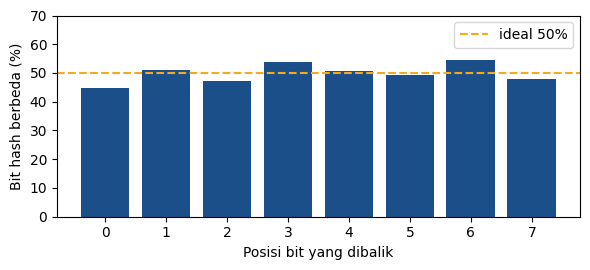

In [ ]:
# Avalanche untuk setiap posisi bit pada byte pertama
hasil = [modern.avalanche_sha256("Kriptografi123456", p)["persen"] for p in range(8)]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(range(8), hasil, color="#1B4F8A")
ax.axhline(50, color="#F5AA1E", ls="--", label="ideal 50%")
ax.set_xlabel("Posisi bit yang dibalik"); ax.set_ylabel("Bit hash berbeda (%)")
ax.set_ylim(0, 70); ax.legend(); fig.tight_layout(); plt.show()

## 4.3 PRNG dan CSPRNG (Pertemuan 5)

In [ ]:
print("LCG seed 42 (panggilan 1):", modern.lcg(42, 3))
print("LCG seed 42 (panggilan 2):", modern.lcg(42, 3), " <- identik, deterministik")
print()
print("CSPRNG (panggilan 1):", modern.csprng_hex())
print("CSPRNG (panggilan 2):", modern.csprng_hex(), " <- selalu berbeda")

LCG seed 42 (panggilan 1): [1250496027, 1116302264, 1000676753]
LCG seed 42 (panggilan 2): [1250496027, 1116302264, 1000676753]  <- identik, deterministik

CSPRNG (panggilan 1): f82566e219335adf
CSPRNG (panggilan 2): 7f54672e918d0773  <- selalu berbeda


## 4.4 Stream Cipher RC4 (Pertemuan 5)

In [ ]:
enc = rc4.rc4(b"Key", b"Plaintext")
print("Cipherteks :", enc.hex(), "(test vector slide: bbf316e8d940af0ad3)")
print("Dekripsi   :", rc4.rc4(b"Key", enc))

Cipherteks : bbf316e8d940af0ad3 (test vector slide: bbf316e8d940af0ad3)
Dekripsi   : b'Plaintext'


In [ ]:
t = rc4.demo_two_time_pad(b"rahasia", b"TRANSFER SERATUS JUTA", b"TRANSFER SATU MILYAR!")
print("C1 xor C2:", t["xor_cipher"].hex())
print("P1 xor P2:", t["xor_plain"].hex())
print("Identik  :", t["sama"], "-> keystream bocor (two-time pad)")

C1 xor C2: 0000000000000000000004061474181a6c13140660
P1 xor P2: 0000000000000000000004061474181a6c13140660
Identik  : True -> keystream bocor (two-time pad)


## 4.5 AES dan Mode Operasi (Pertemuan 6)

### Padding PKCS#7

In [ ]:
for data in (b"KRIPTOGRAFI", b"A" * 16):
    padded, n = aes.padding_pkcs7(data)
    print(f"{len(data):>2} byte -> padding {n:>2} byte (0x{n:02x}), total {len(padded)} byte")
    print("   ", padded.hex(" "))

11 byte -> padding  5 byte (0x05), total 16 byte
    4b 52 49 50 54 4f 47 52 41 46 49 05 05 05 05 05
16 byte -> padding 16 byte (0x10), total 32 byte
    41 41 41 41 41 41 41 41 41 41 41 41 41 41 41 41 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10


### ECB versus CBC pada plainteks berulang

In [ ]:
from Crypto.Cipher import AES

key, iv = b"0123456789ABCDEF", b"FEDCBA9876543210"
plain = b"GAMBARBERULANG!!" * 4
ecb = AES.new(key, AES.MODE_ECB).encrypt(plain)
cbc = AES.new(key, AES.MODE_CBC, iv).encrypt(plain)
print("ECB:", [ecb[i:i+16].hex()[:8] + "..." for i in range(0, 64, 16)], "-> blok identik")
print("CBC:", [cbc[i:i+16].hex()[:8] + "..." for i in range(0, 64, 16)], "-> blok berbeda")

ECB: ['f4010f86...', 'f4010f86...', 'f4010f86...', 'f4010f86...'] -> blok identik
CBC: ['ef2af54b...', 'c1052ed0...', '3a2f9d5c...', '13a5f38b...'] -> blok berbeda


### Enkripsi dan dekripsi teks dengan password (KDF + salt) untuk keempat mode

In [ ]:
pesan = "Pesan rahasia CryptoLab"
baris = []
for mode in aes.MODE:
    r = aes.enkripsi_teks(mode, pesan, "rahasia123", bits=256)
    kembali = aes.dekripsi_teks(mode, r["paket"].hex(), "rahasia123", bits=256)
    baris.append({"Mode": mode, "IV/nonce (hex)": r["iv"].hex() or "-", "Tag": "ada" if r["tag"] else "-",
                  "Panjang cipherteks": len(r["ct"]), "Dekripsi benar": kembali == pesan})
pd.DataFrame(baris)

,Mode,IV/nonce (hex),Tag,Panjang cipherteks,Dekripsi benar
0,ECB,-,-,32,True
1,CBC,a83cc818568baadb9a4d4edea5c235a0,-,32,True
2,CTR,3d2e8172031781aa,-,23,True
3,GCM,d6c29fa759697f413fd8a87b,ada,23,True


### Demo gambar: kebocoran pola ECB

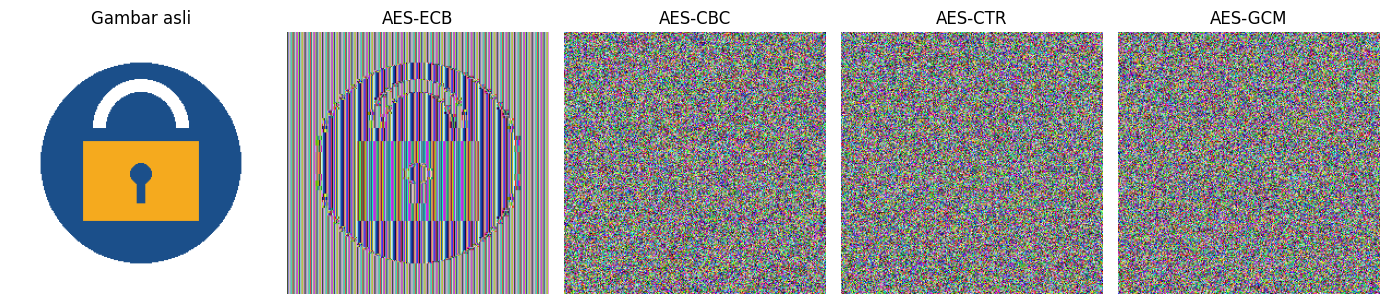

In [ ]:
img = aes.gambar_contoh()
kunci = get_random_bytes(16)

tampil = {"Gambar asli": img}
for mode in ["ECB", "CBC", "CTR", "GCM"]:
    tampil[f"AES-{mode}"] = aes.enkripsi_gambar(img, mode, kunci)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, (judul, g) in zip(axes, tampil.items()):
    ax.imshow(g); ax.set_title(judul); ax.axis("off")
fig.tight_layout()
fig.savefig("images/demo_ecb_cbc.png", dpi=150)
plt.show()

Pada **ECB**, bentuk gembok masih terlihat karena area warna yang sama menghasilkan blok cipherteks yang sama. Pada **CBC, CTR, dan GCM**, seluruh gambar tampak seperti noise acak.

### Uji manipulasi cipherteks: CBC versus GCM

In [ ]:
pesan = "Uang ditransfer 1.000.000 rupiah ke rekening Budi Santoso".encode()
kunci = get_random_bytes(32)

print("Pesan asli :", pesan.decode())
cbc = aes.uji_manipulasi("CBC", pesan, kunci, posisi=0)
print("\nCBC -> terdeteksi:", cbc["terdeteksi"])
print("      hasil dekripsi:", repr(cbc["hasil"]))
gcm = aes.uji_manipulasi("GCM", pesan, kunci, posisi=0)
print("\nGCM -> terdeteksi:", gcm["terdeteksi"], "|", gcm["pesan"])

Pesan asli : Uang ditransfer 1.000.000 rupiah ke rekening Budi Santoso

CBC -> terdeteksi: False
      hasil dekripsi: 'D��f����U/[>���=0.000.000 rupiah ke rekening Budi Santoso'

GCM -> terdeteksi: True | Ditolak: MAC check failed


CBC mendekripsi tanpa peringatan: blok pertama rusak, dan angka pada blok kedua berubah secara terprediksi (*bit-flipping attack*, 1.000.000 menjadi 0.000.000). GCM menolak data karena tag autentikasi tidak cocok.

## 4.6 Rekapitulasi Pengujian

In [ ]:
def gcm_password_salah():
    paket = aes.enkripsi_teks("GCM", "x", "benar")["paket"].hex()
    try:
        aes.dekripsi_teks("GCM", paket, "salah")
        return "diterima"
    except ValueError:
        return "ditolak"


uji = [
    ("Vigenère: KRIPTOGRAFI, kunci KUNCI", "ULVRBYAECNS", klasik.vigenere("KRIPTOGRAFI", "KUNCI")),
    ("Vigenère: MEET ME AT MIDNIGHT, kunci FULLMOON", "RYPEYSOGRCOYUUVG", klasik.vigenere("MEET ME AT MIDNIGHT", "FULLMOON")),
    ("Playfair: GOODBROOMSSWEEPCLEAN, kunci JALAN NAKULA SEBELAS", "FP TS CQ TV TF DV EV DW GW EK SL UX",
        klasik.bagi_pasangan(klasik.playfair("GOODBROOMSSWEEPCLEAN", "JALAN NAKULA SEBELAS"))),
    ("XOR: KRIPTOGRAFI, kunci KUNCI (hex)", "000707131d04121c020f02", modern.xor_cipher(b"KRIPTOGRAFI", b"KUNCI").hex()),
    ("Avalanche SHA-256: bit berbeda", "115", str(modern.avalanche_sha256("Kriptografi123456", 0)["bit_beda"])),
    ("LCG seed 42: dua angka pertama", "[1250496027, 1116302264]", str(modern.lcg(42, 2))),
    ("RC4: kunci Key, plainteks Plaintext (hex)", "bbf316e8d940af0ad3", rc4.rc4(b"Key", b"Plaintext").hex()),
    ("PKCS#7: KRIPTOGRAFI (11 byte), byte padding", "5", str(aes.padding_pkcs7(b"KRIPTOGRAFI")[1])),
    ("AES-GCM: dekripsi dengan password salah", "ditolak", gcm_password_salah()),
]
tabel = pd.DataFrame(uji, columns=["Pengujian", "Yang diharapkan (slide)", "Hasil"])
tabel["Status"] = ["Lulus" if a == b else "Gagal" for a, b in zip(tabel["Yang diharapkan (slide)"], tabel["Hasil"])]
tabel

,Pengujian,Yang diharapkan (slide),Hasil,Status
0,"Vigenère: KRIPTOGRAFI, kunci KUNCI",ULVRBYAECNS,ULVRBYAECNS,Lulus
1,"Vigenère: MEET ME AT MIDNIGHT, kunci FULLMOON",RYPEYSOGRCOYUUVG,RYPEYSOGRCOYUUVG,Lulus
2,"Playfair: GOODBROOMSSWEEPCLEAN, kunci JALAN NA...",FP TS CQ TV TF DV EV DW GW EK SL UX,FP TS CQ TV TF DV EV DW GW EK SL UX,Lulus
3,"XOR: KRIPTOGRAFI, kunci KUNCI (hex)",000707131d04121c020f02,000707131d04121c020f02,Lulus
4,Avalanche SHA-256: bit berbeda,115,115,Lulus
5,LCG seed 42: dua angka pertama,"[1250496027, 1116302264]","[1250496027, 1116302264]",Lulus
6,"RC4: kunci Key, plainteks Plaintext (hex)",bbf316e8d940af0ad3,bbf316e8d940af0ad3,Lulus
7,"PKCS#7: KRIPTOGRAFI (11 byte), byte padding",5,5,Lulus
8,AES-GCM: dekripsi dengan password salah,ditolak,ditolak,Lulus


---
# BAB V. PENUTUP

## 5.1 Cara Menjalankan Aplikasi

Di terminal VS Code, pada folder proyek:

```bash
pip install -r requirements.txt
streamlit run app.py
```

Browser akan terbuka otomatis di `http://localhost:8501`. Pilih modul pada menu sebelah kiri.

## 5.2 Kesimpulan

1. Cipher klasik mudah dipahami dan dihitung, tetapi tidak aman karena pola bahasa tetap tersisa pada cipherteks.
2. Kriptografi modern bekerja pada bit dan byte dengan XOR sebagai operasi inti, dan dinilai lewat avalanche effect (hasil uji SHA-256: 115 dari 256 bit berubah, atau 44,9%).
3. Keamanan stream cipher bergantung pada kualitas dan keunikan keystream. Pemakaian ulang keystream pada RC4 membocorkan XOR kedua plainteks.
4. Algoritma yang kuat seperti AES tetap bisa gagal bila mode operasinya salah: ECB membocorkan pola gambar, sedangkan CBC tidak mendeteksi manipulasi. GCM menyelesaikan keduanya dengan menambahkan autentikasi.

## 5.3 Saran Pengembangan

Aplikasi dapat dikembangkan dengan modul transposisi dan super enkripsi, pemecah Vigenère (Kasiski dan Index of Coincidence), DES, serta kriptografi kunci publik (RSA dan tanda tangan digital) setelah materinya dipelajari.

---
# DAFTAR PUSTAKA

Munir, R. (2019). *Kriptografi* (Edisi Kedua). Bandung: Informatika.

Schneier, B. (2001). *Applied Cryptography*. New York: John Wiley & Sons.

Shannon, C. E. (1949). Communication Theory of Secrecy Systems. *Bell System Technical Journal*.

Stallings, W. (2003). *Cryptography and Network Security*. New Jersey: Prentice Hall.